In [1]:
import os

In [2]:
import meshio
import numpy as np
import deepxde as dde

Using backend: pytorch
Other supported backends: tensorflow.compat.v1, tensorflow, jax, paddle.
paddle supports more examples now and is recommended.


1. Read GMSH 2D File and Extract Coordinate Clouds

In [3]:
mesh = meshio.read("hi1.msh")

# Extract only 2D spatial Coordinates (X, Y), dropping Z channel
all_points = mesh.points[:, 0:2]

print("---Diagnonstics---")
print("Availabel Keys in cell_sets_dict:", list(mesh.cell_sets_dict.keys()))
print("Available Keys in field_data:", list(mesh.field_data.keys()))


---Diagnonstics---
Availabel Keys in cell_sets_dict: []
Available Keys in field_data: ['inlet', 'outlet', 'bottom_wall', 'top_wall', 'fluid']


In [4]:
boundary_pts = {}

# APPROACH A: Try reading via cell_sets_dict (string-based)
if len(mesh.cell_sets_dict) > 0 and "inlet" in mesh.cell_sets_dict:
    for group_name, cell_indices_dict in mesh.cell_sets_dict.items():
        point_indices = []
        for element_type, cell_indices in cell_indices_dict.items():
            actual_cells = mesh.cells_dict[element_type]
            active_cells = actual_cells[cell_indices] 
            point_indices.extend(active_cells.ravel())
        boundary_pts[group_name] = all_points[np.unique(point_indices).astype(int)]
        
# APPROACH B: Fallback via field_data mapping (integer tag-based)
else:
    for name, info in mesh.field_data.items():
        target_id = int(info[0]) # Get the pure integer group ID
        point_indices = []
        
        for cell_type in mesh.cells_dict.keys():
            if "gmsh:physical" in mesh.cell_data_dict and cell_type in mesh.cell_data_dict["gmsh:physical"]:
                cells = mesh.cells_dict[cell_type]
                physical_tags = mesh.cell_data_dict["gmsh:physical"][cell_type]
                
                #check if tags match target_id
                active_cells = cells[np.where(physical_tags == target_id)[0]]
                if len(active_cells) > 0:
                    point_indices.extend(active_cells.ravel())
                    
        boundary_pts[name] = all_points[np.unique(point_indices).astype(int)]
        
# Fallback: Double-check if lowercase/uppercase mismatch exists
sanitized_pts = {k.lower().strip(): v for k, v in boundary_pts.items()}

# Unpack point matrices securely
X_inlet  = sanitized_pts.get("inlet")
X_outlet = sanitized_pts.get("outlet")
X_domain = sanitized_pts.get("fluid")
X_walls  = np.vstack((sanitized_pts.get("bottom_wall"), sanitized_pts.get("top_wall")))

print("\n--- Data Extraction Verification ---")
print(f"Fluid domain points : {X_domain.shape if X_domain is not None else 'MISSING'}")
print(f"Inlet points        : {X_inlet.shape if X_inlet is not None else 'MISSING'}")
print(f"Outlet points       : {X_outlet.shape if X_outlet is not None else 'MISSING'}")
print(f"Wall boundaries     : {X_walls.shape if X_walls is not None else 'MISSING'}")

# Initialize the DeepXDE geometry representation using your parsed domain points
geom = dde.geometry.PointCloud(points=X_domain)


--- Data Extraction Verification ---
Fluid domain points : (4165, 2)
Inlet points        : (21, 2)
Outlet points       : (21, 2)
Wall boundaries     : (334, 2)


In [5]:
print("Available physical groups and IDs:", mesh.field_data)
print("Available cell types in this mesh:", mesh.cells_dict.keys())

Available physical groups and IDs: {'inlet': array([9, 1]), 'outlet': array([10,  1]), 'bottom_wall': array([11,  1]), 'top_wall': array([12,  1]), 'fluid': array([13,  2])}
Available cell types in this mesh: dict_keys(['line', 'triangle'])


2. DEFINE 2D NAVIER-STOKES PDE CONSTRAINTS

In [6]:
def navier_stokes_2d(x, y):
    u = y[:, 0:1]
    v = y[:, 1:2]
    p = y[:, 2:3]
    
    # Fluid Properties (Adjust based on your characteristic Reynolds Number)
    rho = 1.0  # Fluid Density
    mu = 0.01  # Dynamic Viscosity
    
    # First-order gradients (Jacobians)
    du_x = dde.grad.jacobian(y, x, i=0, j=0)
    du_y = dde.grad.jacobian(y, x, i=0, j=1)
    
    dv_x = dde.grad.jacobian(y, x, i=1, j=0)
    dv_y = dde.grad.jacobian(y, x, i=1, j=1)
    
    dp_x = dde.grad.jacobian(y, x, i=2, j=0)
    dp_y = dde.grad.jacobian(y, x, i=2, j=1)
    
    # Second-order gradients (Laplacians)
    du_xx = dde.grad.hessian(y, x, component=0, i=0, j=0)
    du_yy = dde.grad.hessian(y, x, component=0, i=1, j=1)
    
    dv_xx = dde.grad.hessian(y, x, component=1, i=0, j=0)
    dv_yy = dde.grad.hessian(y, x, component=1, i=1, j=1)
    
    # Conservation of Mass (Incompressible Continuity)
    continuity = du_x + dv_y
    
    # Conservation of Momentum (Steady-state Navier-Stokes)
    x_momentum = rho * (u * du_x + v * du_y) + dp_x - mu * (du_xx + du_yy)
    y_momentum = rho * (u * dv_x + v * dv_y) + dp_y - mu * (dv_xx + dv_yy)
    
    return [continuity, x_momentum, y_momentum]

3. ASSIGN MAP BOUNDARY CONDITIONS (BCs)

In [7]:
# Inlet Condition: Uniform velocity entry profile (u = 1.0, v = 0.0)
# 1. Get the number of points in your inlet data set
num_inlet_points = X_inlet.shape[0]

# 2. Create matching column vectors (shape: num_points, 1)
u_inlet_values = np.ones((num_inlet_points, 1)) * 1.0
v_inlet_values = np.zeros((num_inlet_points, 1))

# 3. Pass the structured NumPy arrays into PointSetBC
bc_inlet_u = dde.icbc.PointSetBC(X_inlet, values=u_inlet_values, component=0)
bc_inlet_v = dde.icbc.PointSetBC(X_inlet, values=v_inlet_values, component=1)

# Wall Boundaries: No-slip boundary criteria (u = 0.0, v = 0.0)
bc_wall_u = dde.icbc.PointSetBC(X_walls, values=0.0, component=0)
bc_wall_v = dde.icbc.PointSetBC(X_walls, values=0.0, component=1)

# Outlet Condition: Free relative atmospheric pressure line (p = 0.0)
bc_outlet_p = dde.icbc.PointSetBC(X_outlet, values=0.0, component=2)

bcs = [bc_inlet_u, bc_inlet_v, bc_wall_u, bc_wall_v, bc_outlet_p]


4. DATA PIPELINE & NEURAL NETWORK SETUP

In [8]:
# Combine all your mesh nodes (fluid + boundaries) to act as fixed training anchor points
all_mesh_anchors = np.vstack((X_domain, X_inlet, X_outlet, X_walls))

data = dde.data.PDE(
    geom, 
    navier_stokes_2d, 
    bcs, 
    num_domain=10000,    # Flawless: Generates 10,000 dense points inside your point cloud envelope
    num_boundary=0,      # FIXED: Set to 0 to prevent the PointCloud ValueError!
    anchors=all_mesh_anchors  # Forces training on all 227 + 5 + 5 + 74 original nodes
)

In [9]:
# 1. Print the total combined domain coordinates (Original nodes + the 10,000 generated points)
print("Actual training domain coordinates shape:", data.train_x.shape)

# 2. Print the exact coordinates assigned to your first boundary condition (e.g., Inlet)
# This digs inside the PointSetBC object to pull the raw NumPy array
print("Inlet boundary condition points shape:", data.bcs[0].points.shape)

Actual training domain coordinates shape: (15272, 2)
Inlet boundary condition points shape: (21, 2)


In [10]:
print("--- Final Coordinate Checks ---")
print(f"Fluid Domain Points (Interior)  : {X_domain.shape}")
print(f"Dense Inlet Boundary Points     : {X_inlet.shape}")
print(f"Outlet Boundary Points          : {X_outlet.shape}")
print(f"Wall Boundaries                 : {X_walls.shape}")
print(f"Total compiled PDE train array  : {data.train_x.shape}")

--- Final Coordinate Checks ---
Fluid Domain Points (Interior)  : (4165, 2)
Dense Inlet Boundary Points     : (21, 2)
Outlet Boundary Points          : (21, 2)
Wall Boundaries                 : (334, 2)
Total compiled PDE train array  : (15272, 2)


Check the actual boundary and the points on the boundary

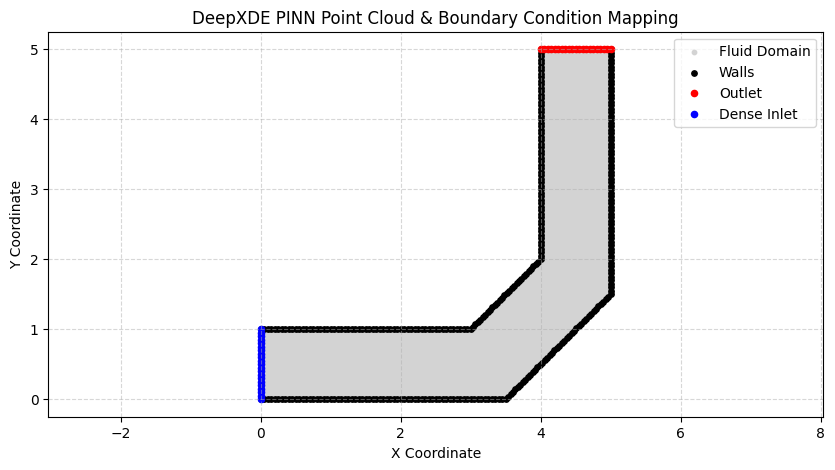

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

# 1. Plot the interior fluid points (Light gray background)
plt.scatter(X_domain[:, 0], X_domain[:, 1], color='lightgray', s=10, label='Fluid Domain')

# 2. Plot the Wall Boundaries (Black dots)
plt.scatter(X_walls[:, 0], X_walls[:, 1], color='black', s=15, label='Walls')

# 3. Plot the Outlet (Red dots)
plt.scatter(X_outlet[:, 0], X_outlet[:, 1], color='red', s=20, label='Outlet')

# 4. Plot your newly increased dense Inlet points (Blue dots)
plt.scatter(X_inlet[:, 0], X_inlet[:, 1], color='blue', s=20, label='Dense Inlet')

# Visual adjustment parameters
plt.xlabel('X Coordinate')
plt.ylabel('Y Coordinate')
plt.title('DeepXDE PINN Point Cloud & Boundary Condition Mapping')
plt.legend(loc='upper right')
plt.axis('equal')
plt.grid(True, linestyle='--', alpha=0.5)

# Save or display the configuration
plt.savefig("pinn_geometry_check.png", dpi=300)
plt.show()


In [15]:
loss_weights = [
    100.0, 10.0, 10.0,      # PDE weights (continuity, x, y, z momentum)
    50.0, 50.0,     # Inlet BC weights (u, v, w) -> Forces flow to enter!
    10.0, 1.0,      # Wall BC weights (u, v, w)
    10.0                      # Outlet BC weight (p)
]


In [16]:
layer_size = [2, 64, 64, 64, 64, 64, 3]
net = dde.nn.FNN(layer_size, "tanh", "Glorot uniform")

model = dde.Model(data, net)


In [17]:
class SoftmaxAdaptiveWeights(dde.callbacks.Callback):
    def __init__(self, model, every_n_epochs=100, alpha_0=1.0, gamma=0.999):
        super().__init__()
        self.model = model
        self.every_n_epochs = every_n_epochs
        self.alpha = alpha_0
        self.gamma = gamma
        self.epoch = 0

    def on_epoch_end(self):
        self.epoch += 1
        if self.epoch % self.every_n_epochs != 0:
            return
        if len(self.model.losshistory.loss_train) == 0:
            return
        current_losses = self.model.losshistory.loss_train[-1]
        exp_terms = np.exp(self.alpha * np.array(current_losses))
        new_weights = exp_terms / (np.sum(exp_terms) + 1e-8)
        self.alpha *= self.gamma
        self.model.loss_weights = new_weights.tolist()
        # print(f"Epoch {self.epoch}: Adaptive weights updated to {new_weights.tolist()}, alpha decayed to {self.alpha:.4f}")

adaptive_callback = SoftmaxAdaptiveWeights(model, every_n_epochs=20)

5. INITIALIZE AND SOLVE MECHANICS

In [20]:
# Stage 1: Coarse Training optimizing with Adam solver
print("Starting optimization stage 1 (Adam)...")
model.compile("adam", lr=1e-3, loss_weights=loss_weights)
losshistory, train_state = model.train(iterations=1000, display_every=200, callbacks=[adaptive_callback])

# Stage 2: Convergence refinement optimizing with L-BFGS solver
dde.optimizers.config.set_LBFGS_options(maxiter=200)
print("Starting optimization stage 2 (L-BFGS)...")
model.compile("L-BFGS", loss_weights= model.loss_weights)
losshistory, train_state = model.train(display_every=100, callbacks=[adaptive_callback])

# Export tracking logs and physical field weight matrices 
dde.saveplot(losshistory, train_state, issave=True, isplot=False)
print("PINN training session finalized successfully!")

Starting optimization stage 1 (Adam)...
Compiling model...
'compile' took 0.001382 s

Training model...

Step      Train loss                                                                          Test loss                                                                           Test metric
3000      [1.62e+00, 3.15e-03, 5.70e-03, 3.62e-01, 3.61e-01, 4.52e-01, 4.53e-03, 7.50e-05]    [1.62e+00, 3.15e-03, 5.70e-03, 3.62e-01, 3.61e-01, 4.52e-01, 4.53e-03, 7.50e-05]    []  
3200      [9.02e-04, 1.34e-05, 1.12e-04, 8.91e-04, 3.28e-04, 8.71e-03, 9.51e-04, 3.37e-07]    [9.02e-04, 1.34e-05, 1.12e-04, 8.91e-04, 3.28e-04, 8.71e-03, 9.51e-04, 3.37e-07]    []  
3400      [1.14e-03, 1.98e-05, 1.52e-04, 9.74e-04, 2.60e-04, 7.40e-03, 7.32e-04, 3.07e-07]    [1.14e-03, 1.98e-05, 1.52e-04, 9.74e-04, 2.60e-04, 7.40e-03, 7.32e-04, 3.07e-07]    []  
3600      [1.51e-03, 3.36e-05, 1.43e-04, 9.76e-04, 3.22e-04, 6.53e-03, 6.58e-04, 2.21e-07]    [1.51e-03, 3.36e-05, 1.43e-04, 9.76e-04, 3.22e-04, 6.53e-03, 6


Generating fluid flow fields mapped exactly onto your L-shaped pipe geometry...


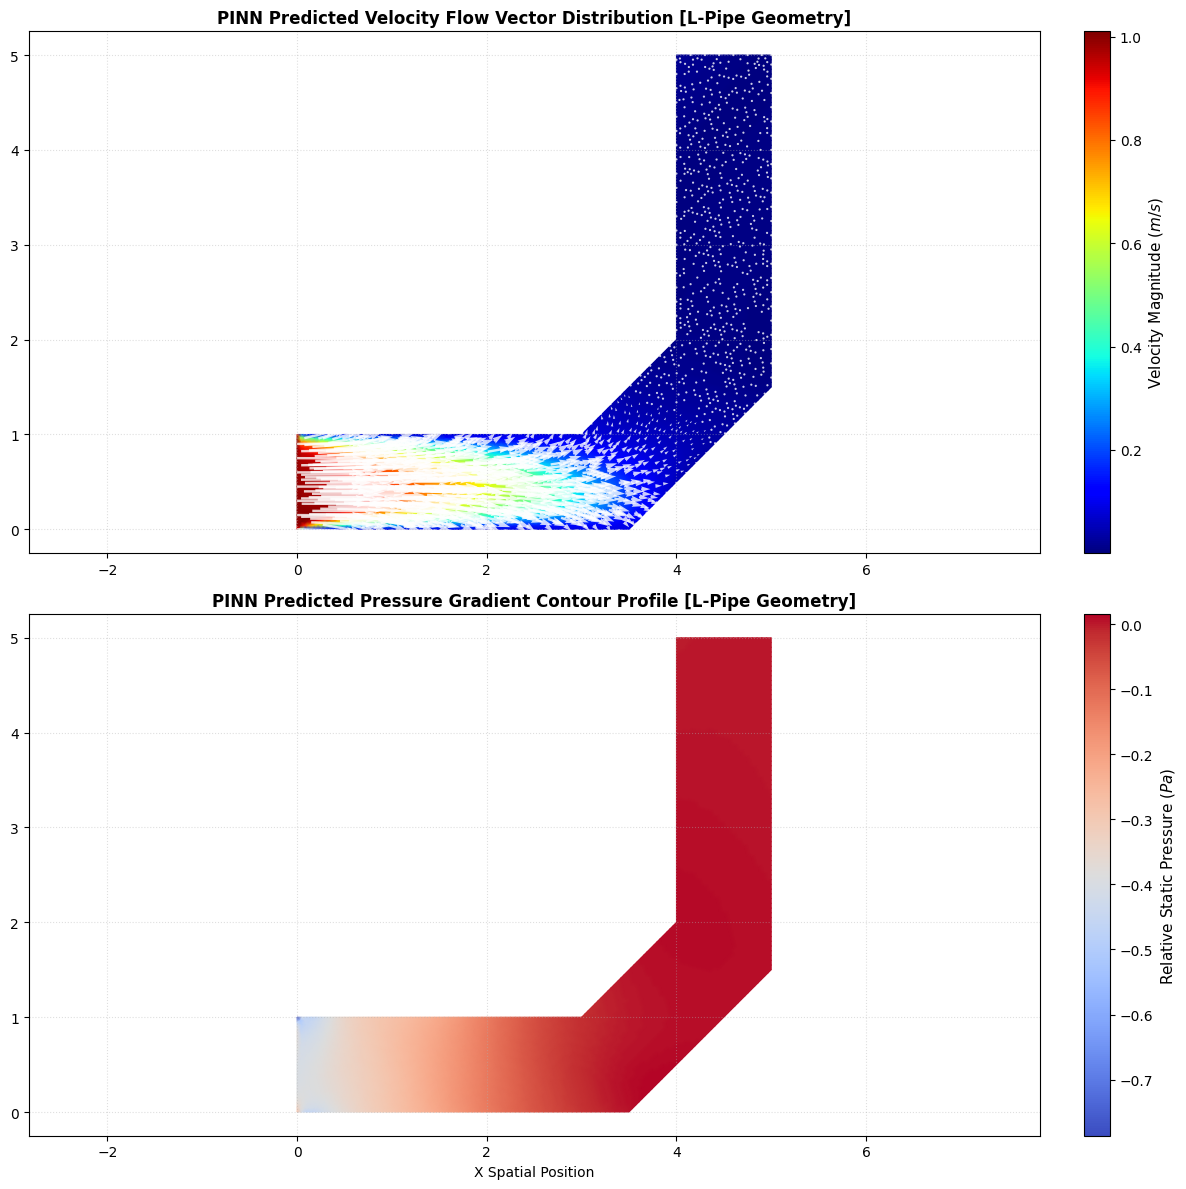

L-shaped fluid dynamics profiles saved successfully as 'pinn_l_pipe_flow_results.png'!


In [21]:
import matplotlib.tri as tri

# ==========================================
# 6. L-SHAPE EXACT GEOMETRY FLOW VISUALIZATION
# ==========================================
print("\nGenerating fluid flow fields mapped exactly onto your L-shaped pipe geometry...")

# Pull the precise structural mesh triangles generated by Gmsh to lock boundaries down
fluid_cell_type = "triangle"
fluid_group_id = int(mesh.field_data["fluid"][0])
global_triangles = mesh.cells_dict[fluid_cell_type]
physical_tags = mesh.cell_data_dict["gmsh:physical"][fluid_cell_type]

# Filter down to only keep triangles that belong to the "fluid" physical domain
active_fluid_triangles = global_triangles[physical_tags == fluid_group_id]

# Extract the coordinate list and query the network for predictions on these points
viz_points = mesh.points[:, 0:2]
prediction = model.predict(viz_points)
u_pred = prediction[:, 0]
v_pred = prediction[:, 1]
p_pred = prediction[:, 2]
vel_magnitude = np.sqrt(u_pred**2 + v_pred**2)

# Pass the original Gmsh triangles directly into Matplotlib to guarantee shape continuity
triangulation = tri.Triangulation(viz_points[:, 0], viz_points[:, 1], triangles=active_fluid_triangles)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 12))

# --- Subplot 1: Velocity Magnitude Map On the True L-Pipe Shape ---
vel_map = ax1.tripcolor(triangulation, vel_magnitude, cmap='jet', shading='gouraud')
cbar_vel = fig.colorbar(vel_map, ax=ax1, fraction=0.046, pad=0.04)
cbar_vel.set_label('Velocity Magnitude ($m/s$)', fontsize=11)

# Superimpose directional flow vector arrows matching your mesh node layout
# (Subsampled index steps to prevent vector cluttering on screen)
ax1.quiver(viz_points[::3, 0], viz_points[::3, 1], u_pred[::3], v_pred[::3], color='white', alpha=0.8, scale=15)
ax1.set_title('PINN Predicted Velocity Flow Vector Distribution [L-Pipe Geometry]', fontsize=12, fontweight='bold')
ax1.axis('equal')
ax1.grid(True, linestyle=':', alpha=0.4)

# --- Subplot 2: Pressure Drop Map On the True L-Pipe Shape ---
pres_map = ax2.tripcolor(triangulation, p_pred, cmap='coolwarm', shading='gouraud')
cbar_pres = fig.colorbar(pres_map, ax=ax2, fraction=0.046, pad=0.04)
cbar_pres.set_label('Relative Static Pressure ($Pa$)', fontsize=11)

ax2.set_title('PINN Predicted Pressure Gradient Contour Profile [L-Pipe Geometry]', fontsize=12, fontweight='bold')
ax2.set_xlabel('X Spatial Position', fontsize=10)
ax2.axis('equal')
ax2.grid(True, linestyle=':', alpha=0.4)

plt.tight_layout()
plt.savefig("pinn_l_pipe_flow_results.png", dpi=300, bbox_inches='tight')
plt.show()

print("L-shaped fluid dynamics profiles saved successfully as 'pinn_l_pipe_flow_results.png'!")